# State of Data Brazil 2024: perfil dos profissionais de dados e previsão de faixa salarial

Pergunta do projeto: que características dos profissionais de dados se relacionam com a faixa salarial, e o quanto é possível prever essa faixa a partir delas?

# Importações e parâmetros

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from imblearn.under_sampling import RandomUnderSampler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GridSearchCV, train_test_split

In [2]:
ARQUIVO_DE_DADOS = 'Final Dataset - State of Data 2024 - Kaggle - df_survey_2024.csv'
COLUNA_ALVO = '2.h_faixa_salarial'
SEMENTE = 42
PROPORCAO_DE_TESTE = 0.2

GRADE_DE_HIPERPARAMETROS = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30, None],
    'min_samples_leaf': [1, 2, 4],
    'class_weight': ['balanced'],
}

# As 13 faixas da pesquisa reunidas em 6 grupos, juntando faixas vizinhas com poucos respondentes
AGRUPAMENTO_EM_6_FAIXAS = {
    'Menos de R$ 1.000/mês': 'Até R$ 2.000/mês',
    'de R$ 1.001/mês a R$ 2.000/mês': 'Até R$ 2.000/mês',
    'de R$ 2.001/mês a R$ 3.000/mês': 'de R$ 2.001/mês a R$ 4.000/mês',
    'de R$ 3.001/mês a R$ 4.000/mês': 'de R$ 2.001/mês a R$ 4.000/mês',
    'de R$ 4.001/mês a R$ 6.000/mês': 'de R$ 4.001/mês a R$ 6.000/mês',
    'de R$ 6.001/mês a R$ 8.000/mês': 'de R$ 6.001/mês a R$ 12.000/mês',
    'de R$ 8.001/mês a R$ 12.000/mês': 'de R$ 6.001/mês a R$ 12.000/mês',
    'de R$ 12.001/mês a R$ 16.000/mês': 'de R$ 12.001/mês a R$ 20.000/mês',
    'de R$ 16.001/mês a R$ 20.000/mês': 'de R$ 12.001/mês a R$ 20.000/mês',
    'de R$ 20.001/mês a R$ 25.000/mês': 'Acima de R$ 20.001/mês',
    'de R$ 25.001/mês a R$ 30.000/mês': 'Acima de R$ 20.001/mês',
    'de R$ 30.001/mês a R$ 40.000/mês': 'Acima de R$ 20.001/mês',
    'Acima de R$ 40.001/mês': 'Acima de R$ 20.001/mês',
}

# Versão com 5 grupos: junta as duas faixas entre R$ 2 mil e R$ 6 mil
UNIAO_PARA_5_FAIXAS = {
    'de R$ 2.001/mês a R$ 4.000/mês': 'de R$ 2.001/mês a R$ 6.000/mês',
    'de R$ 4.001/mês a R$ 6.000/mês': 'de R$ 2.001/mês a R$ 6.000/mês',
}

MACROFAIXAS = {
    'Até R$ 2.000/mês': '1. Base (Até 4k)',
    'de R$ 2.001/mês a R$ 4.000/mês': '1. Base (Até 4k)',
    'de R$ 4.001/mês a R$ 6.000/mês': '2. Intermediário (4k-12k)',
    'de R$ 6.001/mês a R$ 12.000/mês': '2. Intermediário (4k-12k)',
}
MACROFAIXA_DO_RESTANTE = '3. Especialista (Acima de 12k)'

## Funções auxiliares

Os passos que se repetem em vários experimentos (dividir os dados, treinar e avaliar, buscar hiperparâmetros, escolher variáveis pela correlação) ficam aqui, uma vez só.

In [3]:
def codificar(rotulos):
    """Transforma rótulos de texto em códigos inteiros (em ordem alfabética; vazio vira -1)."""
    return rotulos.astype('category').cat.codes


def dividir_treino_e_teste(X, y):
    return train_test_split(X, y, test_size=PROPORCAO_DE_TESTE, random_state=SEMENTE, stratify=y)


def preencher_com_mediana(tabela):
    return tabela.fillna(tabela.median())


def desenhar_matriz_de_confusao(y_real, y_previsto):
    plt.figure(figsize=(8, 6))
    sns.heatmap(confusion_matrix(y_real, y_previsto), annot=True, fmt='d', cmap='Blues')
    plt.title('Matriz de Confusão: Real vs Predito')
    plt.xlabel('Predito')
    plt.ylabel('Real')
    plt.show()


resultados = {}


def avaliar(nome, modelo, divisao, nomes_das_classes=None, X_treino=None, y_treino=None, mostrar_matriz=False):
    """Treina (se receber dados de treino), mostra o relatório no teste e guarda acurácia e F1 ponderado."""
    X_treino_padrao, X_teste, y_treino_padrao, y_teste = divisao
    if X_treino is None:
        X_treino, y_treino = X_treino_padrao, y_treino_padrao
    modelo.fit(X_treino, y_treino)
    previsto = modelo.predict(X_teste)

    resultados[nome] = {'Acurácia': accuracy_score(y_teste, previsto),
                        'F1 ponderado': f1_score(y_teste, previsto, average='weighted')}
    print(f"{nome}\nAcurácia Global: {resultados[nome]['Acurácia']:.2%}\n")
    print(classification_report(y_teste, previsto, target_names=nomes_das_classes))
    if mostrar_matriz:
        desenhar_matriz_de_confusao(y_teste, previsto)
    return modelo


def buscar_hiperparametros(nome, divisao, nomes_das_classes=None):
    """Busca em grade com validação cruzada de 5 partições, otimizando o F1 ponderado."""
    busca = GridSearchCV(RandomForestClassifier(random_state=SEMENTE), GRADE_DE_HIPERPARAMETROS,
                         cv=5, n_jobs=-1, scoring='f1_weighted')
    busca.fit(divisao[0], divisao[2])
    print(f"Melhores parâmetros: {busca.best_params_}")
    print(f"Melhor F1 ponderado na validação cruzada: {busca.best_score_:.2f}\n")
    avaliar(nome, busca.best_estimator_, divisao, nomes_das_classes, X_treino=divisao[0], y_treino=divisao[2])
    return busca


def selecionar_por_correlacao(variaveis, alvo_codificado, quantas_positivas, quantas_negativas):
    """Escolhe as variáveis com as maiores correlações positivas e negativas com o alvo."""
    correlacoes = variaveis.corrwith(alvo_codificado)
    selecionadas = correlacoes.nlargest(quantas_positivas).index.tolist() + correlacoes.nsmallest(quantas_negativas).index.tolist()
    for variavel in selecionadas:
        print(f"- {variavel}: {correlacoes[variavel]:.2f}")
    return selecionadas


def grafico_de_correlacoes(correlacoes, titulo, tamanho):
    tabela = correlacoes.reset_index()
    tabela.columns = ['Variável', 'Correlação']
    plt.figure(figsize=tamanho)
    sns.barplot(data=tabela, x='Correlação', y='Variável', hue='Variável', palette='RdBu_r', legend=False)
    plt.axvline(0, color='black', lw=1)
    plt.title(titulo, fontsize=16)
    plt.xlabel('Coeficiente de Correlação', fontsize=12)
    plt.ylabel('Variáveis', fontsize=12)
    plt.tight_layout()
    plt.show()

# Análise exploratória

Nesta seção será abordada a análise exploratória dos dados.
A execução não interfere no treinamento do modelo.

In [4]:
pesquisa = pd.read_csv(ARQUIVO_DE_DADOS)
print(pesquisa.shape, ": tamanho do conjunto de dados")
pesquisa.head()

(5217, 403) : tamanho do conjunto de dados


,0.a_token,0.d_data/hora_envio,1.a_idade,1.a.1_faixa_idade,1.b_genero,1.c_cor/raca/etnia,1.d_pcd,1.e_experiencia_profissional_prejudicada,1.e.1_Não acredito que minha experiência profissional seja afetada,"1.e.2_Sim, devido a minha Cor/Raça/Etnia",...,"8.d.3_Entrando em contato com os times de negócio para definição do problema, identificar a solução e apresentação de resultados.",8.d.4_Desenvolvendo modelos de Machine Learning com o objetivo de colocar em produção em sistemas (produtos de dados).,"8.d.5_Colocando modelos em produção, criando os pipelines de dados, APIs de consumo e monitoramento.","8.d.6_Cuidando da manutenção de modelos de Machine Learning já em produção, atuando no monitoramento, ajustes e refatoração quando necessário.","8.d.7_Realizando construções de dashboards em ferramentas de BI como PowerBI, Tableau, Looker, Qlik, etc.","8.d.8_Utilizando ferramentas avançadas de estatística como SAS, SPSS, Stata etc, para realizar análises.","8.d.9_Criando e dando manutenção em ETLs, DAGs e automações de pipelines de dados.",8.d.10_Criando e gerenciando soluções de Feature Store e cultura de MLOps.,"8.d.11_Criando e mantendo a infra que meus modelos e soluções rodam (clusters, servidores, API, containers, etc.)",8.d.12_Treinando e aplicando LLM's para solucionar problemas de negócio.
0,reb94rv0msth7q4nreb94riaq80iz3yi,16/10/2024 11:19:17,18,17-21,Masculino,Branca,Não,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1zc66g69jjt49y32l1zc66g8wqj79m4e,16/10/2024 20:45:31,18,17-21,Masculino,Branca,Não,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,uu99wmam4n5kc2uu99wmydf0rk7l58f7,17/10/2024 18:10:59,18,17-21,Masculino,Parda,Não,Não acredito que minha experiência profissiona...,1.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3ynsw7z0hl5hhpbfvaeqk73ynsw7z04l,22/10/2024 18:03:00,18,17-21,Masculino,Branca,Não,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,v6bji2ct5xckpl1uouv6bjiotkrf3b4f,23/10/2024 01:33:23,18,17-21,Masculino,Branca,Não,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
pesquisa.info(verbose=True)
pesquisa.describe(include='all').T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5217 entries, 0 to 5216
Data columns (total 403 columns):
 #    Column                                                                                                                                                                                               Dtype  
---   ------                                                                                                                                                                                               -----  
 0    0.a_token                                                                                                                                                                                            object 
 1    0.d_data/hora_envio                                                                                                                                                                                  object 
 2    1.a_idade                                 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
0.a_token,5217,5215,lb7gt5hdqqxuguv2lb7gto44mpk3ejha,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0.d_data/hora_envio,5217,5188,14/10/2024 17:37:10,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1.a_idade,5217.0,NaN,NaN,NaN,32.358827,7.419433,18.0,27.0,31.0,36.0,68.0
1.a.1_faixa_idade,5217,9,30-34,1503,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1.b_genero,5217,4,Masculino,3968,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
"8.d.8_Utilizando ferramentas avançadas de estatística como SAS, SPSS, Stata etc, para realizar análises.",773.0,NaN,NaN,NaN,0.003881,0.062217,0.0,0.0,0.0,0.0,1.0
"8.d.9_Criando e dando manutenção em ETLs, DAGs e automações de pipelines de dados.",773.0,NaN,NaN,NaN,0.043984,0.205193,0.0,0.0,0.0,0.0,1.0
8.d.10_Criando e gerenciando soluções de Feature Store e cultura de MLOps.,773.0,NaN,NaN,NaN,0.009056,0.094791,0.0,0.0,0.0,0.0,1.0
"8.d.11_Criando e mantendo a infra que meus modelos e soluções rodam (clusters, servidores, API, containers, etc.)",773.0,NaN,NaN,NaN,0.011643,0.107342,0.0,0.0,0.0,0.0,1.0


Considerando o total de 5217 entrevistados, com a tabela acima é possível aferir que:

- O dataset contém dados de pessoas de 18 a 68 anos.
- Cerca de 75% dos participantes são do sexo masculino.
- Cerca de 67% são brancos.
- Dos que não vivem no Brasil, a maioria mora em Portugal.
- 30% ocupam cargos de nível sênior e 21% ocupam cargo de gestor.
- 180 são PCD (cerca de 3,45%)

2.h_faixa_salarial
de R$ 8.001/mês a R$ 12.000/mês     1080
de R$ 12.001/mês a R$ 16.000/mês     716
de R$ 6.001/mês a R$ 8.000/mês       656
de R$ 4.001/mês a R$ 6.000/mês       593
de R$ 16.001/mês a R$ 20.000/mês     456
NaN                                  354
de R$ 3.001/mês a R$ 4.000/mês       270
de R$ 20.001/mês a R$ 25.000/mês     246
de R$ 2.001/mês a R$ 3.000/mês       237
de R$ 25.001/mês a R$ 30.000/mês     159
de R$ 30.001/mês a R$ 40.000/mês     158
de R$ 1.001/mês a R$ 2.000/mês       155
Acima de R$ 40.001/mês               104
Menos de R$ 1.000/mês                 33
Name: count, dtype: int64


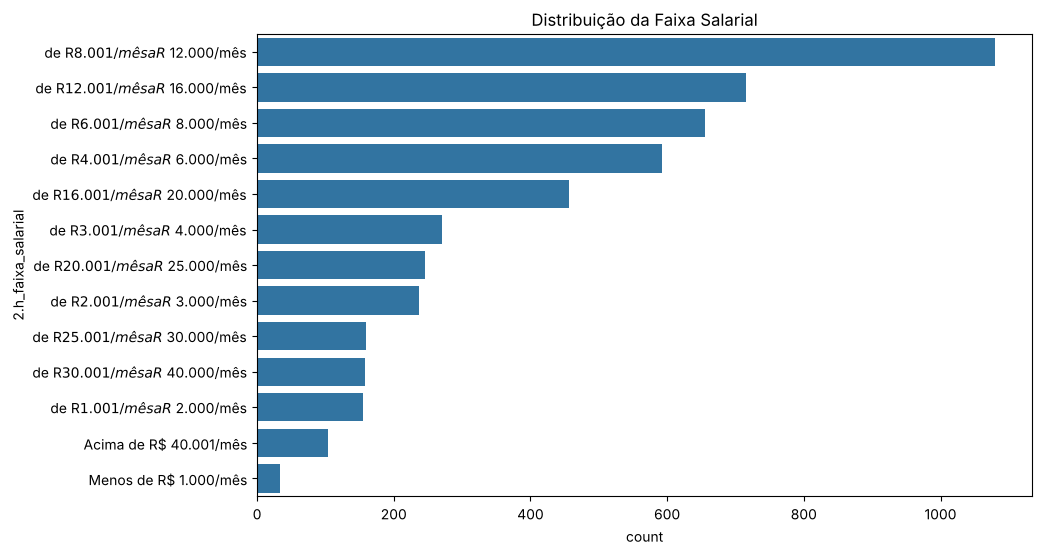

In [6]:
print(pesquisa[COLUNA_ALVO].value_counts(dropna=False))

plt.figure(figsize=(10, 6))
sns.countplot(y=pesquisa[COLUNA_ALVO], order=pesquisa[COLUNA_ALVO].value_counts().index)
plt.title('Distribuição da Faixa Salarial')
plt.show()

Análise de correlação entre variáveis com a finalidade de identificar quais serão usadas para o treinamento

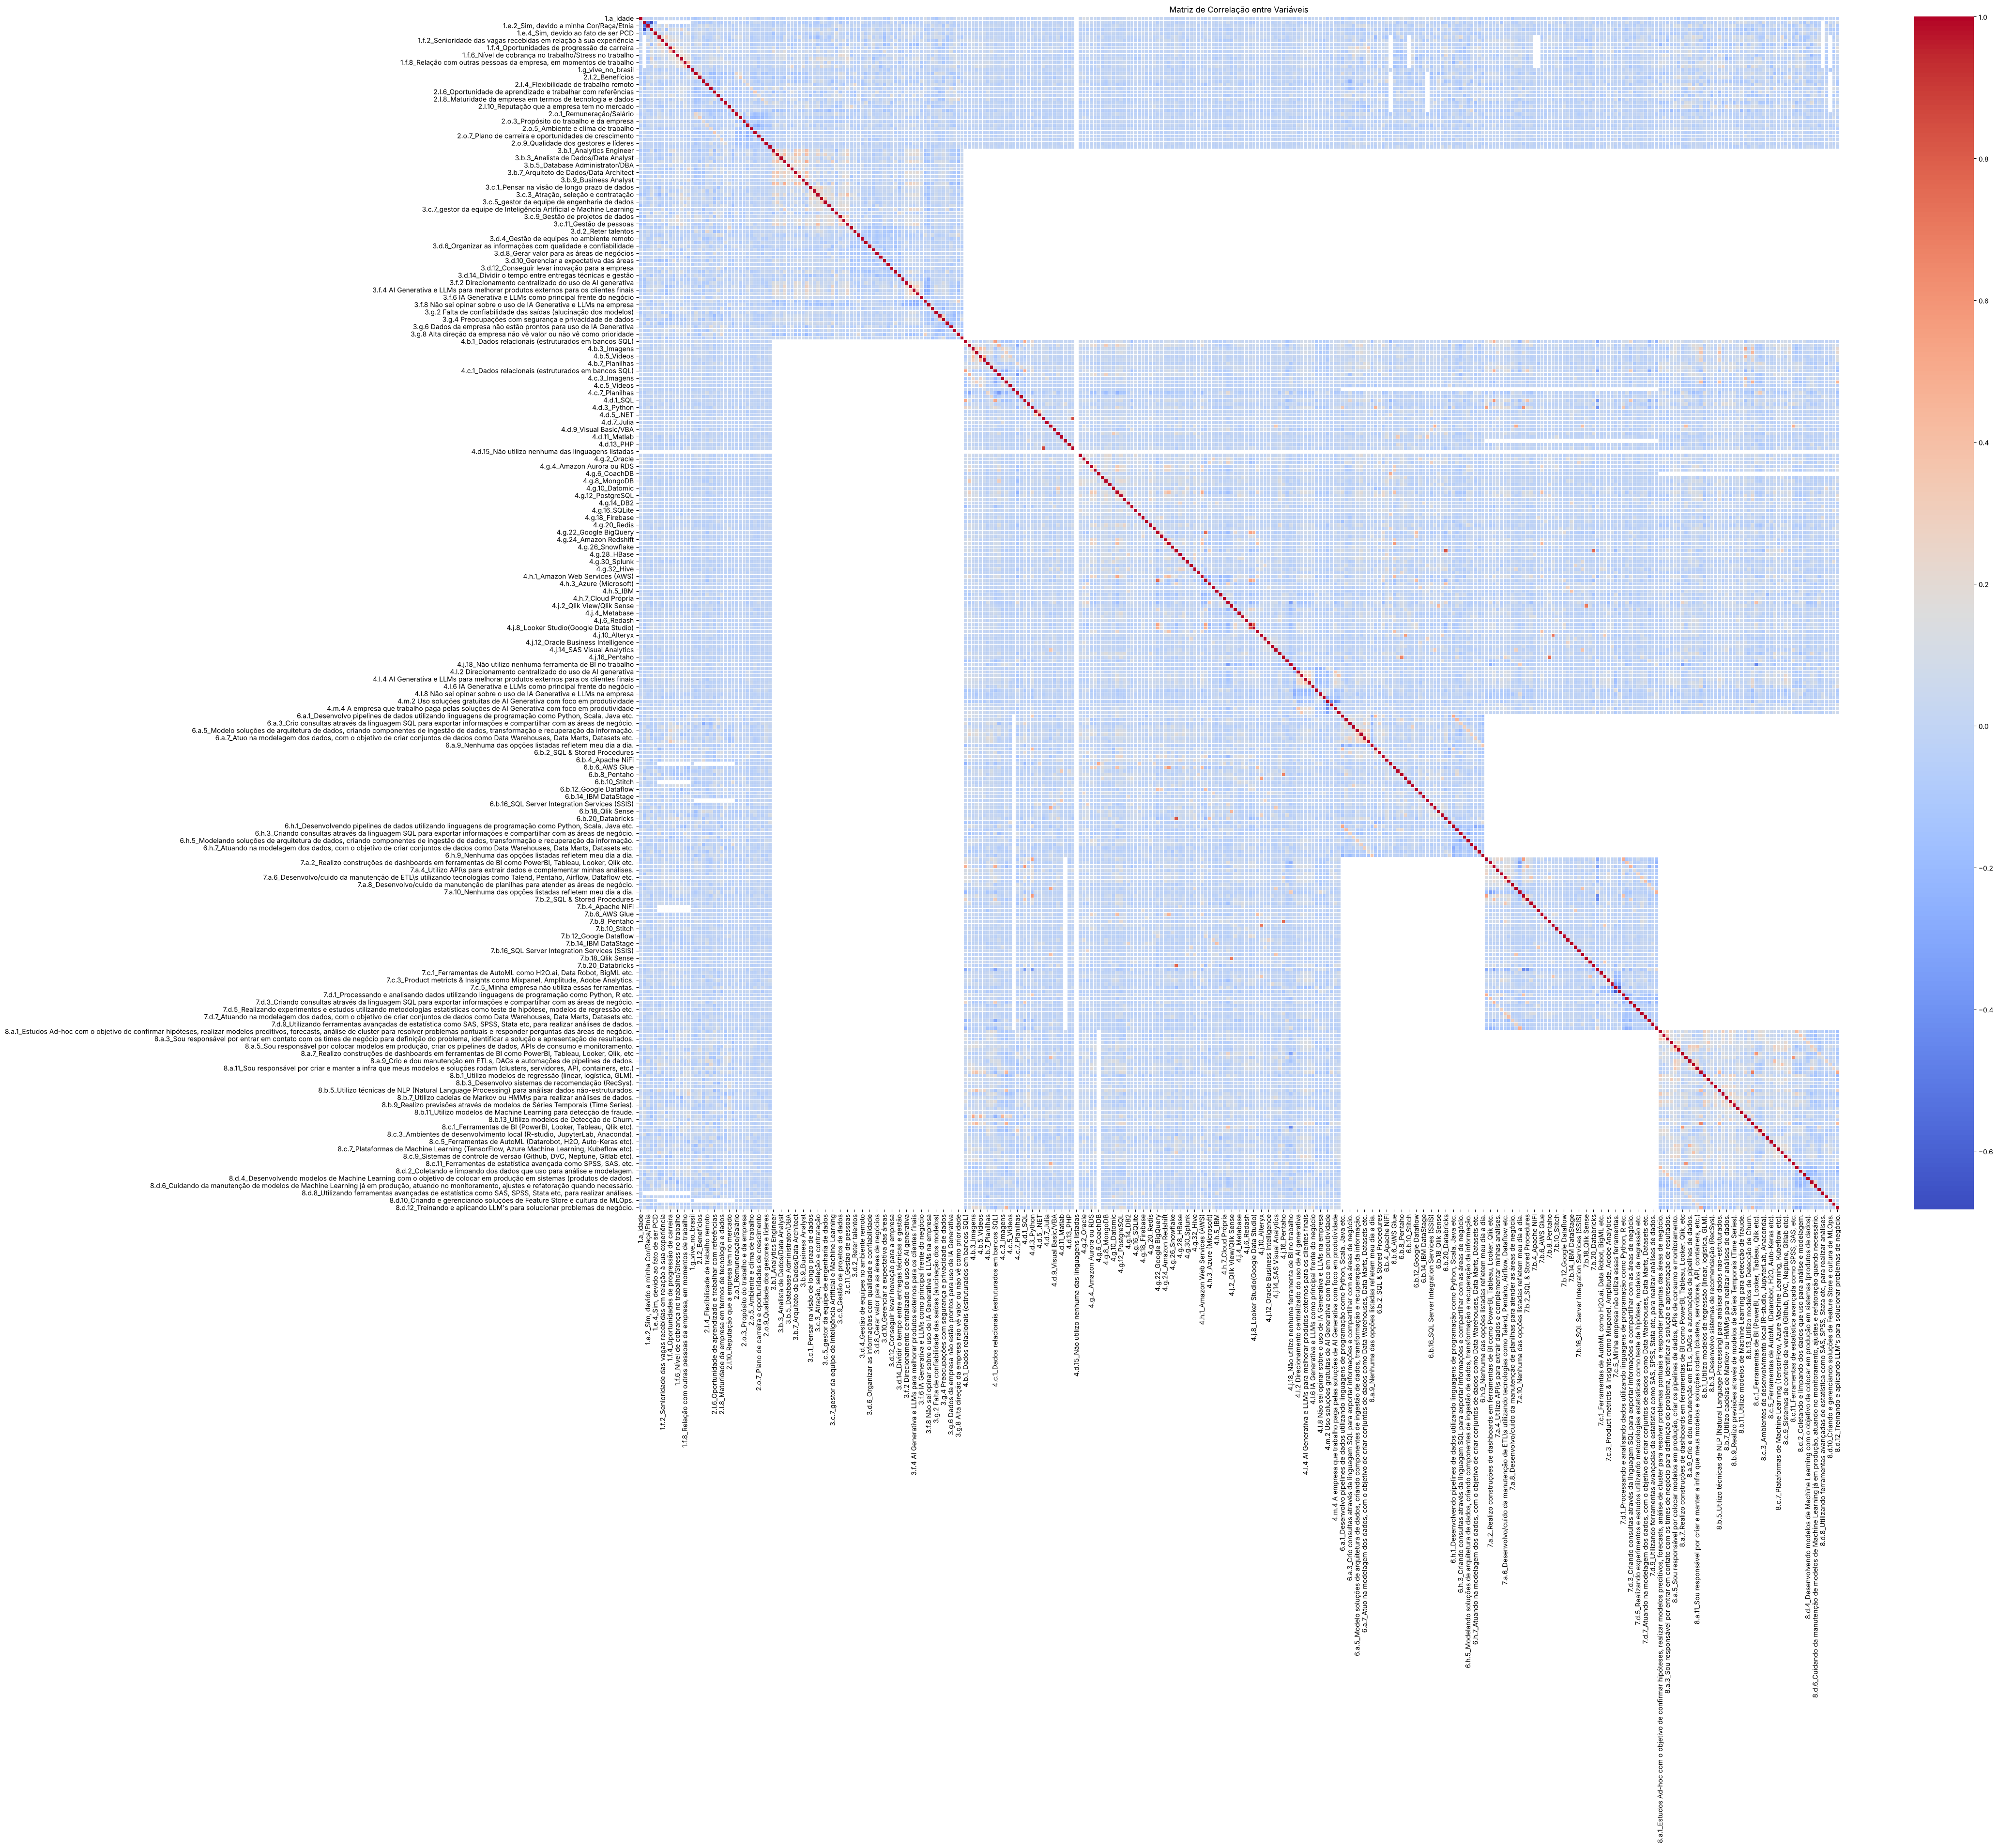

Pares com maior correlação positiva:


4.d.6_Java                                                          4.d.14_JavaScript                                             0.866511
4.g.27_Databricks                                                   6.b.20_Databricks                                             0.824234
4.j.7_Looker                                                        4.j.8_Looker Studio(Google Data Studio)                       0.819009
4.g.27_Databricks                                                   7.b.20_Databricks                                             0.773082
4.j.16_Pentaho                                                      7.b.8_Pentaho                                                 0.754918
4.g.22_Google BigQuery                                              4.h.2_Google Cloud (GCP)                                      0.745298
4.j.10_Alteryx                                                      7.b.9_Alteryx                                                 0.722458
4.j.2_Qlik View/Qlik Sense 

Pares com maior correlação negativa:


1.e.1_Não acredito que minha experiência profissional seja afetada       1.e.3_Sim, devido a minha identidade de gênero                                                -0.682380
7.c.5_Minha empresa não utiliza essas ferramentas.                       7.c.6_Não sei informar.                                                                       -0.603616
1.e.1_Não acredito que minha experiência profissional seja afetada       1.e.2_Sim, devido a minha Cor/Raça/Etnia                                                      -0.503715
4.j.18_Não utilizo nenhuma ferramenta de BI no trabalho                  8.c.1_Ferramentas de BI (PowerBI, Looker, Tableau, Qlik etc).                                 -0.451160
4.m.2 Uso soluções gratuitas de AI Generativa com foco em produtividade  4.m.4 A empresa que trabalho paga pelas soluções de AI Generativa com foco em produtividade   -0.437624
7.b.1_Scripts Python                                                     7.b.21_Não utilizo ferramentas de ETL     

In [7]:
correlacoes = pesquisa.corr(numeric_only=True)

plt.figure(figsize=(40, 32))
sns.heatmap(correlacoes, cmap='coolwarm', linewidths=0.5)   # azul: correlação negativa, vermelho: positiva
plt.title('Matriz de Correlação entre Variáveis')
plt.show()

pares = correlacoes.where(np.triu(np.ones(correlacoes.shape), k=1).astype(bool)).stack()
print("Pares com maior correlação positiva:")
display(pares.nlargest(10))
print("Pares com maior correlação negativa:")
display(pares.nsmallest(10))

Os pares com maior correlação estão relacionados a tecnologias utilizadas em conjunto.

/tmp/claude-0/-home-claude/0789caf2-d6b0-5bf0-8249-1cffd10d831d/scratchpad/venv/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/tmp/claude-0/-home-claude/0789caf2-d6b0-5bf0-8249-1cffd10d831d/scratchpad/venv/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3038: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


Correlação da Faixa Salarial com as outras variáveis:
7.a.3_Crio consultas através da linguagem SQL para exportar informações e compartilhar com as áreas de negócio.       0.126682
8.c.2_Planilhas (Excel, Google Sheets etc).                                                                           0.111910
1.f.2_Senioridade das vagas recebidas em relação à sua experiência                                                    0.108707
7.d.3_Criando consultas através da linguagem SQL para exportar informações e compartilhar com as áreas de negócio.    0.108459
6.a.3_Crio consultas através da linguagem SQL para exportar informações e compartilhar com as áreas de negócio.       0.102777
                                                                                                                        ...   
3.c.7_gestor da equipe de Inteligência Artificial e Machine Learning                                                 -0.144620
3.b.1_Analytics Engineer                                 

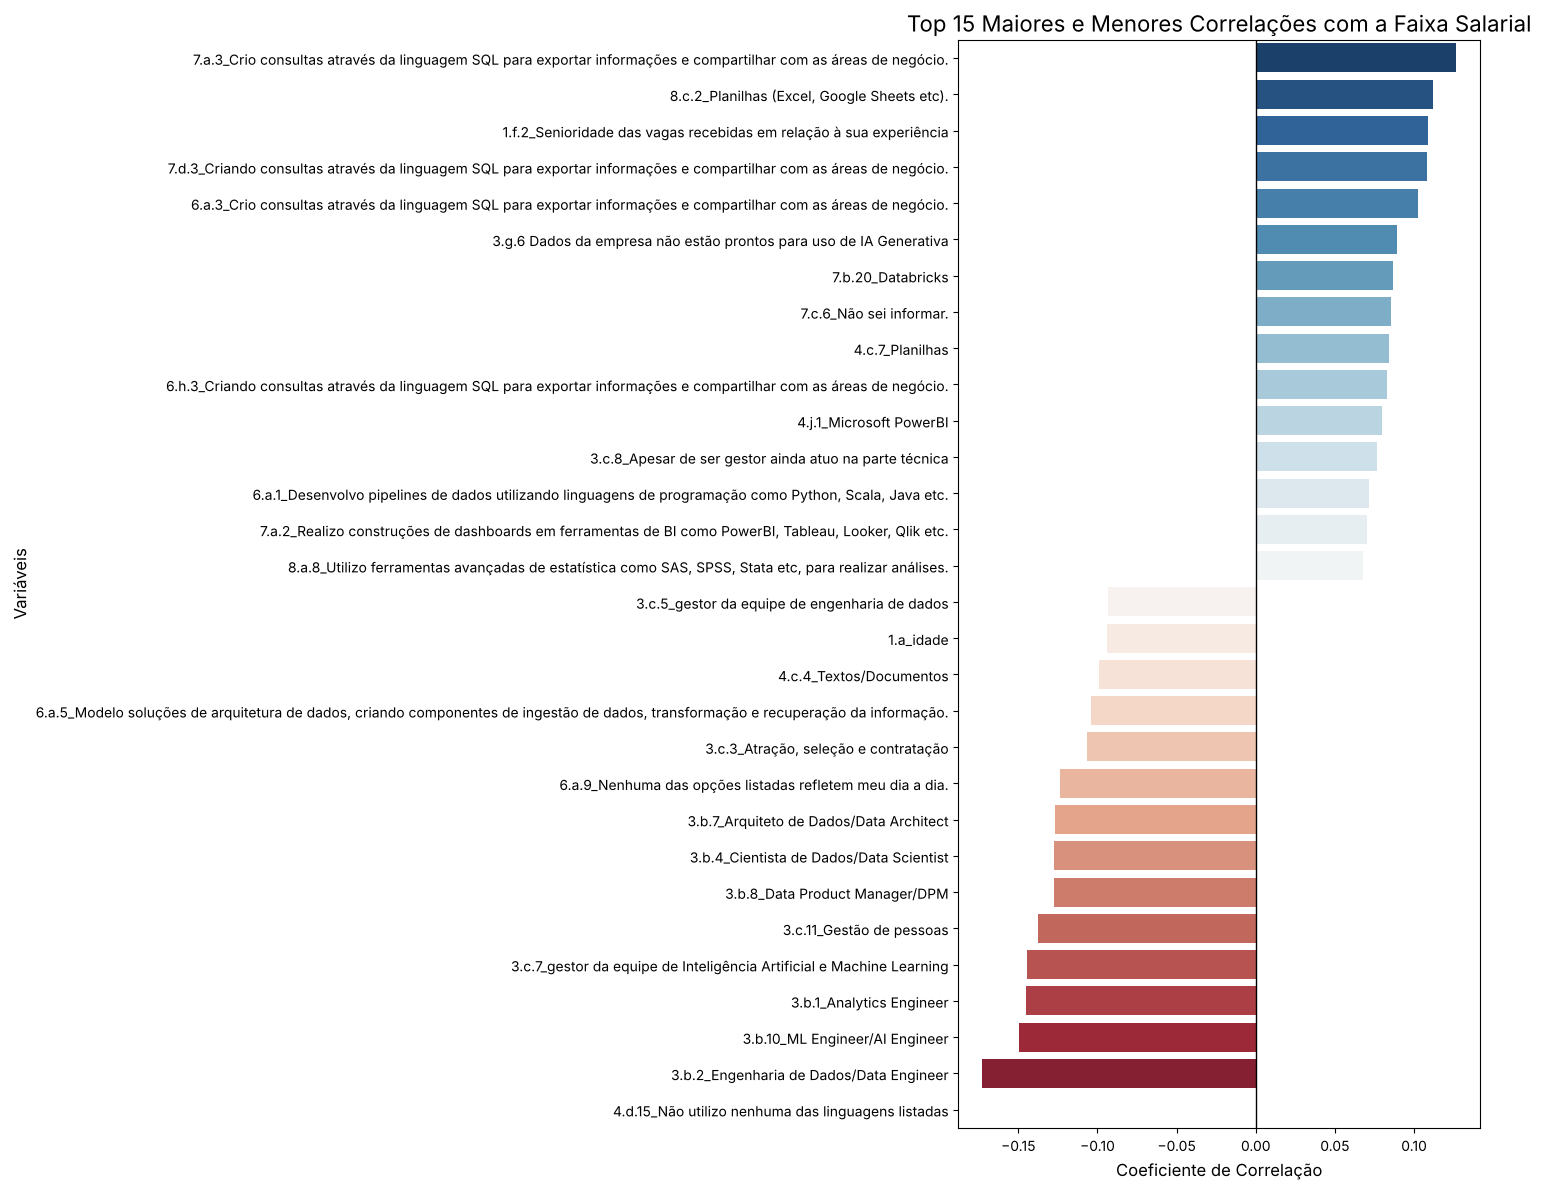

In [8]:
correlacoes_com_a_faixa = pesquisa.select_dtypes(include=[np.number]).corrwith(codificar(pesquisa[COLUNA_ALVO])).sort_values(ascending=False)
print("Correlação da Faixa Salarial com as outras variáveis:")
print(correlacoes_com_a_faixa)

grafico_de_correlacoes(pd.concat([correlacoes_com_a_faixa.head(15), correlacoes_com_a_faixa.tail(15)]),
                       'Top 15 Maiores e Menores Correlações com a Faixa Salarial', tamanho=(15, 12))

# Treinamento do modelo

Nesta versão, quem não informou a faixa salarial entra como uma classe a mais (código -1).

In [9]:
pesquisa_codificada = pesquisa.copy()
pesquisa_codificada['faixa_codificada'] = codificar(pesquisa[COLUNA_ALVO])
variaveis = preencher_com_mediana(pesquisa.select_dtypes(include=[np.number]))

faixas_agrupadas = pesquisa[COLUNA_ALVO].replace(AGRUPAMENTO_EM_6_FAIXAS)
print(faixas_agrupadas.value_counts().sort_index())

2.h_faixa_salarial
Acima de R$ 20.001/mês               667
Até R$ 2.000/mês                     188
de R$ 12.001/mês a R$ 20.000/mês    1172
de R$ 2.001/mês a R$ 4.000/mês       507
de R$ 4.001/mês a R$ 6.000/mês       593
de R$ 6.001/mês a R$ 12.000/mês     1736
Name: count, dtype: int64


## 1. Todas as faixas salariais

14 classes, 100 árvores
Acurácia Global: 31.23%

              precision    recall  f1-score   support

          -1       1.00      1.00      1.00        71
           0       0.25      0.05      0.08        21
           1       0.00      0.00      0.00         7
           2       0.40      0.06      0.11        31
           3       0.26      0.25      0.26       143
           4       0.22      0.20      0.21        91
           5       0.21      0.13      0.16        47
           6       0.22      0.14      0.17        49
           7       0.67      0.06      0.11        32
           8       0.29      0.07      0.12        54
           9       0.25      0.12      0.17        32
          10       0.24      0.32      0.28       119
          11       0.21      0.12      0.15       131
          12       0.29      0.56      0.38       216

    accuracy                           0.31      1044
   macro avg       0.32      0.22      0.23      1044
weighted avg       0.32      0.

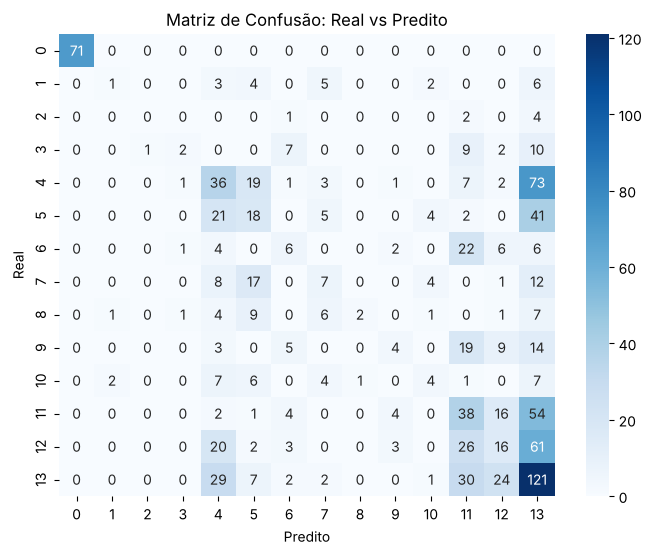

14 classes, 50 árvores com pesos balanceados
Acurácia Global: 30.46%

              precision    recall  f1-score   support

          -1       1.00      1.00      1.00        71
           0       0.25      0.10      0.14        21
           1       0.50      0.14      0.22         7
           2       0.40      0.13      0.20        31
           3       0.23      0.21      0.22       143
           4       0.22      0.23      0.23        91
           5       0.28      0.17      0.21        47
           6       0.23      0.12      0.16        49
           7       0.14      0.03      0.05        32
           8       0.09      0.04      0.05        54
           9       0.11      0.06      0.08        32
          10       0.26      0.32      0.29       119
          11       0.24      0.15      0.19       131
          12       0.28      0.52      0.36       216

    accuracy                           0.30      1044
   macro avg       0.30      0.23      0.24      1044
weighted a

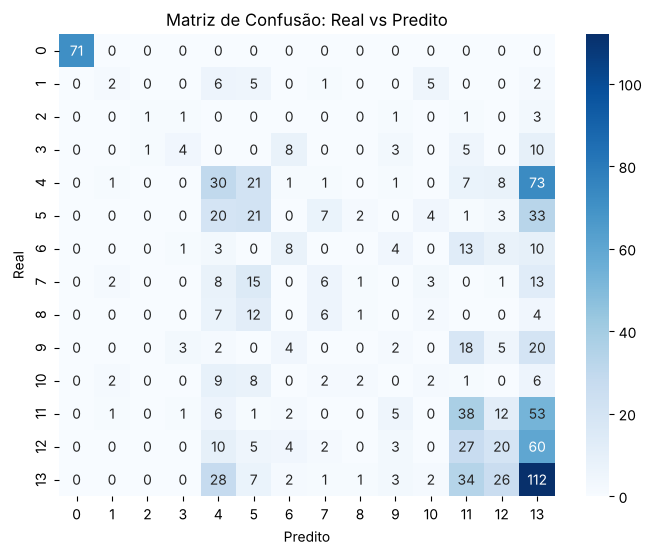

In [10]:
divisao_14 = dividir_treino_e_teste(variaveis, pesquisa_codificada['faixa_codificada'])
avaliar('14 classes, 100 árvores', RandomForestClassifier(n_estimators=100, random_state=SEMENTE), divisao_14, mostrar_matriz=True)
avaliar('14 classes, 50 árvores com pesos balanceados',
        RandomForestClassifier(n_estimators=50, random_state=SEMENTE, class_weight='balanced'), divisao_14, mostrar_matriz=True);

In [11]:
# Subamostragem: reduz as classes maiores no treino para o modelo não favorecer a faixa mais comum
X_reduzido, y_reduzido = RandomUnderSampler(random_state=SEMENTE).fit_resample(divisao_14[0], divisao_14[2])
avaliar('14 classes com subamostragem',
        RandomForestClassifier(n_estimators=80, max_depth=10, class_weight='balanced_subsample', random_state=SEMENTE),
        divisao_14, X_treino=X_reduzido, y_treino=y_reduzido);

14 classes com subamostragem
Acurácia Global: 20.59%

              precision    recall  f1-score   support

          -1       0.49      1.00      0.65        71
           0       0.14      0.24      0.18        21
           1       0.11      0.57      0.18         7
           2       0.06      0.16      0.09        31
           3       0.22      0.19      0.20       143
           4       0.11      0.05      0.07        91
           5       0.06      0.06      0.06        47
           6       0.19      0.12      0.15        49
           7       0.12      0.19      0.15        32
           8       0.08      0.13      0.10        54
           9       0.14      0.22      0.17        32
          10       0.15      0.08      0.10       119
          11       0.20      0.17      0.18       131
          12       0.27      0.18      0.21       216

    accuracy                           0.21      1044
   macro avg       0.17      0.24      0.18      1044
weighted avg       0.20   

## 2. Três macrofaixas

In [12]:
# Quem não informou a faixa cai em "Especialista" (a regra só reconhece as faixas mais baixas)
pesquisa_codificada['macro_codificada'] = codificar(faixas_agrupadas.map(MACROFAIXAS).fillna(MACROFAIXA_DO_RESTANTE))
NOMES_DAS_MACROFAIXAS = sorted(set(MACROFAIXAS.values()) | {MACROFAIXA_DO_RESTANTE})
divisao_macro = dividir_treino_e_teste(variaveis, pesquisa_codificada['macro_codificada'])
avaliar('3 macrofaixas, todas as variáveis', RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=SEMENTE),
        divisao_macro, NOMES_DAS_MACROFAIXAS);

3 macrofaixas, todas as variáveis
Acurácia Global: 70.69%

                                precision    recall  f1-score   support

              1. Base (Até 4k)       0.70      0.24      0.35       139
     2. Intermediário (4k-12k)       0.64      0.85      0.73       466
3. Especialista (Acima de 12k)       0.83      0.70      0.76       439

                      accuracy                           0.71      1044
                     macro avg       0.72      0.60      0.61      1044
                  weighted avg       0.72      0.71      0.69      1044



In [13]:
# Atenção: a seleção usa todas as colunas numéricas, inclusive a faixa codificada, que vaza o alvo (resultado descartado)
pesquisa_codificada['faixa_codificada'] = codificar(faixas_agrupadas)
numericas = pesquisa_codificada.select_dtypes(include=[np.number]).drop(columns=['macro_codificada'])
print("Variáveis selecionadas pela correlação com a macrofaixa:")
variaveis_da_macrofaixa = selecionar_por_correlacao(numericas, pesquisa_codificada['macro_codificada'], quantas_positivas=5, quantas_negativas=8)
divisao_macro_enxuta = dividir_treino_e_teste(preencher_com_mediana(pesquisa_codificada[variaveis_da_macrofaixa]), pesquisa_codificada['macro_codificada'])
avaliar('3 macrofaixas, 13 variáveis', RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=SEMENTE),
        divisao_macro_enxuta, NOMES_DAS_MACROFAIXAS);

Variáveis selecionadas pela correlação com a macrofaixa:
- 3.b.2_Engenharia de Dados/Data Engineer: 0.34
- 1.a_idade: 0.34
- 3.c.11_Gestão de pessoas: 0.30
- 3.b.4_Cientista de Dados/Data Scientist: 0.29
- 3.b.7_Arquiteto de Dados/Data Architect: 0.26
- faixa_codificada: -0.55
- 4.c.7_Planilhas: -0.22
- 2.l.1_Remuneração/Salário: -0.20
- 4.m.2 Uso soluções gratuitas de AI Generativa com foco em produtividade: -0.19
- 4.j.1_Microsoft PowerBI: -0.18
- 8.d.7_Realizando construções de dashboards em ferramentas de BI como PowerBI, Tableau, Looker, Qlik, etc.: -0.17
- 3.f.8 Não sei opinar sobre o uso de IA Generativa e LLMs na empresa: -0.16
- 2.o.7_Plano de carreira e oportunidades de crescimento: -0.15


/tmp/claude-0/-home-claude/0789caf2-d6b0-5bf0-8249-1cffd10d831d/scratchpad/venv/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/tmp/claude-0/-home-claude/0789caf2-d6b0-5bf0-8249-1cffd10d831d/scratchpad/venv/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3038: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


3 macrofaixas, 13 variáveis
Acurácia Global: 99.33%

                                precision    recall  f1-score   support

              1. Base (Até 4k)       0.98      0.97      0.97       139
     2. Intermediário (4k-12k)       1.00      1.00      1.00       466
3. Especialista (Acima de 12k)       0.99      0.99      0.99       439

                      accuracy                           0.99      1044
                     macro avg       0.99      0.99      0.99      1044
                  weighted avg       0.99      0.99      0.99      1044



# Testes de hiperparâmetros

In [14]:
buscar_hiperparametros('3 macrofaixas, 13 variáveis, melhores hiperparâmetros', divisao_macro_enxuta, NOMES_DAS_MACROFAIXAS);

Melhores parâmetros: {'class_weight': 'balanced', 'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 300}
Melhor F1 ponderado na validação cruzada: 0.99



3 macrofaixas, 13 variáveis, melhores hiperparâmetros
Acurácia Global: 99.43%

                                precision    recall  f1-score   support

              1. Base (Até 4k)       0.99      0.97      0.98       139
     2. Intermediário (4k-12k)       1.00      1.00      1.00       466
3. Especialista (Acima de 12k)       0.99      1.00      0.99       439

                      accuracy                           0.99      1044
                     macro avg       0.99      0.99      0.99      1044
                  weighted avg       0.99      0.99      0.99      1044



## 3. Seis classes agrupadas

In [15]:
faixas_5 = faixas_agrupadas.replace(UNIAO_PARA_5_FAIXAS)
pesquisa_codificada['faixa_codificada'] = codificar(faixas_5)
numericas = pesquisa_codificada.select_dtypes(include=[np.number]).drop(columns=['faixa_codificada'])
print("Variáveis selecionadas pela correlação com as faixas agrupadas:")
variaveis_das_5_faixas = selecionar_por_correlacao(numericas, pesquisa_codificada['faixa_codificada'], quantas_positivas=5, quantas_negativas=5)
divisao_5 = dividir_treino_e_teste(preencher_com_mediana(pesquisa_codificada[variaveis_das_5_faixas]), pesquisa_codificada['faixa_codificada'])
nomes = ['Não Mapeado/NaN'] + sorted(faixas_5.dropna().unique())
buscar_hiperparametros('6 classes, 10 variáveis, melhores hiperparâmetros', divisao_5, nomes);

Variáveis selecionadas pela correlação com as faixas agrupadas:
- 3.f.8 Não sei opinar sobre o uso de IA Generativa e LLMs na empresa: 0.17
- 3.d.14_Dividir o tempo entre entregas técnicas e gestão: 0.16
- 3.c.8_Apesar de ser gestor ainda atuo na parte técnica: 0.14
- 4.c.7_Planilhas: 0.13
- 8.c.2_Planilhas (Excel, Google Sheets etc).: 0.13
- macro_codificada: -0.57
- 3.b.10_ML Engineer/AI Engineer: -0.34
- 3.b.4_Cientista de Dados/Data Scientist: -0.32
- 3.b.2_Engenharia de Dados/Data Engineer: -0.28
- 3.c.11_Gestão de pessoas: -0.27


/tmp/claude-0/-home-claude/0789caf2-d6b0-5bf0-8249-1cffd10d831d/scratchpad/venv/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/tmp/claude-0/-home-claude/0789caf2-d6b0-5bf0-8249-1cffd10d831d/scratchpad/venv/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3038: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


Melhores parâmetros: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 100}
Melhor F1 ponderado na validação cruzada: 0.54

6 classes, 10 variáveis, melhores hiperparâmetros
Acurácia Global: 62.55%

                                  precision    recall  f1-score   support

                 Não Mapeado/NaN       0.49      1.00      0.65        71
          Acima de R$ 20.001/mês       0.57      0.50      0.54       133
                Até R$ 2.000/mês       0.26      0.97      0.41        38
de R$ 12.001/mês a R$ 20.000/mês       0.75      0.56      0.64       235
  de R$ 2.001/mês a R$ 6.000/mês       0.38      0.01      0.03       220
 de R$ 6.001/mês a R$ 12.000/mês       0.76      0.99      0.86       347

                        accuracy                           0.63      1044
                       macro avg       0.53      0.67      0.52      1044
                    weighted avg       0.61      0.63      0.56      1044



# Comparação dos experimentos

In [16]:
pd.DataFrame(resultados).T.round(4)

,Acurácia,F1 ponderado
"14 classes, 100 árvores",0.3123,0.2861
"14 classes, 50 árvores com pesos balanceados",0.3046,0.2833
14 classes com subamostragem,0.2059,0.1895
"3 macrofaixas, todas as variáveis",0.7069,0.6915
"3 macrofaixas, 13 variáveis",0.9933,0.9933
"3 macrofaixas, 13 variáveis, melhores hiperparâmetros",0.9943,0.9942
"6 classes, 10 variáveis, melhores hiperparâmetros",0.6255,0.5627
